# 09 — Cap rule and two-stage hybrid (FD001)

**Question:** capping fixes the error near failure but hurts healthy engines. Can two models together get both right?

**Final model (two-stage hybrid):**

```
last 70 cycles ──> capped LSTM ──> p
                                   │
             p ≤ 115 ──────────────┴────────────── p > 115
             answer = p                            q = uncapped LSTM (last 30 cycles)
                                                   answer = larger of q and p
```

- The **capped LSTM** (Srijan, notebook 08) is the expert near failure.
- It was trained never to say much above 125, so a prediction above **115** means "this engine looks healthy". Those engines go to the **uncapped LSTM** (Akhil, notebook 07), which can say 200 or 300.
- We keep the larger of the two answers: the gate already judged the engine healthy, so a lower number would contradict it.

This notebook trains only the rejected classifier design (section 5). Everything else is built from the prediction files in `results/`. Seeds are paired: capped seed *s* goes with uncapped seed *s*; each pair is scored, then averaged over the 5 pairs. Spread (±) is the sample standard deviation over seeds (ddof 1). Test labels are **not** loaded here (only in notebook 10).

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import torch
from torch import nn
import train as T
from evaluation import CUTOFFS, rmse
from load_data import SENSORS
from models_lstm import LSTMRegressor

RESULTS = "../results"
LATE = 125
GATE = 115
SEEDS_FINAL = [0, 1, 2, 3, 4]
SEEDS_EXP = [0, 1, 2]
SEED_COLS = [f"seed_{s}" for s in SEEDS_FINAL]

y_val = T.val_rul()
is_late = y_val <= LATE
print("validation points:", len(y_val), " early:", int((~is_late).sum()), " late:", int(is_late.sum()))


def load_preds(name):
    # (val, test) arrays of shape (5 seeds, 100), in cycles
    v = pd.read_csv(f"{RESULTS}/val_predictions_{name}.csv")
    t = pd.read_csv(f"{RESULTS}/test_predictions_{name}.csv")
    assert (v[["engine_id", "cycle"]].values == CUTOFFS[["engine_id", "cycle"]].values).all()
    assert (t["engine_id"].values == T.test_engine_ids()).all()
    return v[SEED_COLS].to_numpy().T, t[SEED_COLS].to_numpy().T


def score_full(y, p):
    # 'Late' (true RUL <= 125) is the positive class for precision and recall.
    y, p = np.asarray(y), np.asarray(p)
    out = T.score_bands(y, p)
    out["r2"] = r2_score(y, p)
    late, pred_late = y <= LATE, p <= LATE
    tp, fp, fn = (late & pred_late).sum(), (~late & pred_late).sum(), (late & ~pred_late).sum()
    out["late_precision"] = tp / max(tp + fp, 1)
    out["late_recall"] = tp / max(tp + fn, 1)
    return out


def summarise_full(preds):
    df = pd.DataFrame([score_full(y_val, p) for p in preds])
    row = df.mean().to_dict()
    row["rmse_std"] = df["rmse"].std(ddof=1) if len(df) > 1 else 0.0
    return row


def gated(capped, fallback, gate=GATE):
    # capped prediction > gate -> larger of fallback and capped, else capped
    return np.where(capped > gate, np.maximum(fallback, capped), capped)


unc_val, unc_test = load_preds("lstm_uncapped")
cap_val, cap_test = load_preds("lstm_capped")
print("loaded: uncapped", unc_val.shape, " capped", cap_val.shape)

validation points: 100  early: 22  late: 78
loaded: uncapped (5, 100)  capped (5, 100)


## 1. Why far-from-failure engines are hard

`sensor_4` (scaled) against the true RUL for 5 training engines. Far from failure (right of the line at 125) the sensor is flat noise: an engine with 300 cycles left looks like one with 150 left. It only starts to rise in the last ~125 cycles. No model can read a number from a flat signal, which is why every model's early error is large.

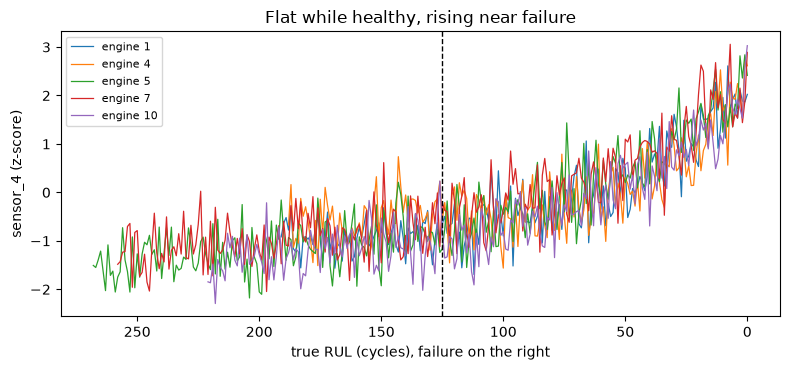

In [2]:
d = T._data()
engines = d["fit_engines"][:5]
s4 = SENSORS.index("sensor_4")
fig, ax = plt.subplots(figsize=(8, 3.8))
for e in engines:
    ax.plot(d["rul"][e], d["arrays"][e][:, s4], lw=0.9, label=f"engine {e}")
ax.axvline(LATE, ls="--", c="k", lw=1)
ax.invert_xaxis()
ax.set_xlabel("true RUL (cycles), failure on the right")
ax.set_ylabel("sensor_4 (z-score)")
ax.set_title("Flat while healthy, rising near failure")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Cap rule (validation)

Pre-registered in Phase 1 (2026-10-21): adopt capping only if, on validation, **overall RMSE is no worse AND late RMSE is better** than without the cap. It was written down before any result, so the goalposts can't move.

In [3]:
cap_rule = pd.DataFrame({"LSTM uncapped": summarise_full(unc_val), "LSTM capped": summarise_full(cap_val)}).T
display(cap_rule[["rmse", "rmse_std", "early_rmse", "late_rmse"]].round(2))
u, c = cap_rule.loc["LSTM uncapped"], cap_rule.loc["LSTM capped"]
overall_ok, late_ok = c["rmse"] <= u["rmse"], c["late_rmse"] < u["late_rmse"]
print(f"overall no worse: {overall_ok}  ({c['rmse']:.2f} vs {u['rmse']:.2f})")
print(f"late better     : {late_ok}  ({c['late_rmse']:.2f} vs {u['late_rmse']:.2f})")
print("cap rule:", "PASS" if overall_ok and late_ok else "FAIL")

,rmse,rmse_std,early_rmse,late_rmse
LSTM uncapped,36.28,3.14,62.96,23.78
LSTM capped,39.79,0.59,81.35,12.72


overall no worse: False  (39.79 vs 36.28)
late better     : True  (12.72 vs 23.78)
cap rule: FAIL


## 3. Gate threshold (validation, 5 seed pairs)

For each gate: how many points go to the uncapped model, how many **late** points are wrongly sent there (*missed late*: a near-failure engine treated as healthy, the dangerous mistake), and the hybrid's RMSE.

In [4]:
gate_rows = []
for g in (100, 110, 115, 120):
    sent, missed, missed_rul, rm, late_rm = [], [], [], [], []
    for s in range(len(SEEDS_FINAL)):
        fired = cap_val[s] > g
        h = gated(cap_val[s], unc_val[s], g)
        sent.append(int(fired.sum()))
        missed.append(int((fired & is_late).sum()))
        missed_rul += list(y_val[fired & is_late])
        rm.append(rmse(y_val, h))
        late_rm.append(rmse(y_val[is_late], h[is_late]))
    gate_rows.append({
        "gate": g, "sent_to_uncapped_mean": np.mean(sent), "missed_late_mean": np.mean(missed),
        "missed_late_per_seed": " ".join(map(str, missed)),
        "missed_true_rul_min": min(missed_rul) if missed_rul else np.nan,
        "missed_true_rul_max": max(missed_rul) if missed_rul else np.nan,
        "rmse_mean": np.mean(rm), "rmse_std": np.std(rm, ddof=1), "late_rmse_mean": np.mean(late_rm),
    })
gates = pd.DataFrame(gate_rows)
gates.to_csv(f"{RESULTS}/experiments_gate.csv", index=False)
gates.round(2)

,gate,sent_to_uncapped_mean,missed_late_mean,missed_late_per_seed,missed_true_rul_min,missed_true_rul_max,rmse_mean,rmse_std,late_rmse_mean
0,100,41.4,20.6,19 22 19 20 23,66,121,33.37,2.65,17.70
1,110,26.8,9.2,9 10 9 9 9,84,121,33.45,2.52,16.35
2,115,17.2,4.6,5 4 6 3 5,89,121,34.78,2.27,15.15
3,120,6.0,1.8,2 0 2 3 2,108,121,39.23,0.59,13.98


## 4. Hybrid prediction files (gate 115)

The gate is applied to validation **and** test predictions. No test labels are needed: the test file only holds predictions, for notebook 10.

In [5]:
def write_preds(name, val, test):
    v = pd.DataFrame(val.T, columns=SEED_COLS)
    v.insert(0, "cycle", CUTOFFS["cycle"].values)
    v.insert(0, "engine_id", CUTOFFS["engine_id"].values)
    t = pd.DataFrame(test.T, columns=SEED_COLS)
    t.insert(0, "engine_id", T.test_engine_ids())
    v.to_csv(f"{RESULTS}/val_predictions_{name}.csv", index=False)
    t.to_csv(f"{RESULTS}/test_predictions_{name}.csv", index=False)
    print(f"wrote {name}: val {v.shape}, test {t.shape}")


hyb_val, hyb_test = gated(cap_val, unc_val), gated(cap_test, unc_test)
write_preds("two_stage_hybrid", hyb_val, hyb_test)

hybrid = pd.DataFrame({
    "LSTM uncapped": summarise_full(unc_val),
    "LSTM capped": summarise_full(cap_val),
    "Two-stage hybrid": summarise_full(hyb_val),
}).T
hybrid[["mae", "rmse", "rmse_std", "r2", "early_rmse", "late_rmse", "late_precision", "late_recall"]].round(2)

wrote two_stage_hybrid: val (100, 7), test (100, 6)


,mae,rmse,rmse_std,r2,early_rmse,late_rmse,late_precision,late_recall
LSTM uncapped,23.48,36.28,3.14,0.64,62.96,23.78,0.93,0.86
LSTM capped,21.25,39.79,0.59,0.57,81.35,12.72,0.79,1.00
Two-stage hybrid,20.32,34.78,2.27,0.67,68.40,15.15,0.87,0.95


## 5. Rejected design: a separate early/late classifier (3 seeds, validation, W = 70)

Instead of using the capped model's own number as the gate, train two new models:

- a **classifier**: `LSTMRegressor` 1 × 64 with one logit output, trained with binary cross-entropy on "true RUL > 125"; "early" if sigmoid > 0.5
- a **late regressor**: the same LSTM trained only on rows with RUL ≤ 125, output clipped to [0, 125]

Early answers are scored as 125. Same recipe as `train.fit` (Adam lr 0.001, batch 128, clipping 1.0, LR halving, early stopping on the 16 held-out engines with patience 15), only the loss and target change for the classifier.

In [6]:
def fit_classifier(X_fit, y_fit, X_es, y_es, seed):
    # Same recipe as train.fit, with BCE on the label "true RUL > 125".
    T.set_seed(seed)
    model = LSTMRegressor(units=64, layers=1)
    t_fit, t_es = (y_fit > LATE).float(), (y_es > LATE).float()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)
    loss_fn = nn.BCEWithLogitsLoss()
    best, best_state, since = float("inf"), None, 0
    for epoch in range(1, T.MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(X_fit))
        for i in range(0, len(order), T.BATCH):
            idx = order[i:i + T.BATCH]
            opt.zero_grad()
            loss_fn(model(X_fit[idx]), t_fit[idx]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            es_loss = float(loss_fn(model(X_es), t_es))
        sched.step(es_loss)
        if es_loss < best - T.MIN_DELTA:
            best, best_state, since = es_loss, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            since += 1
            if since >= T.PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model


w = T.get_windows(70)
late_fit, late_es = w["y_fit"] <= LATE, w["y_es"] <= LATE
cls_rows = []
for s in SEEDS_EXP:
    clf = fit_classifier(w["X_fit"], w["y_fit"], w["X_es"], w["y_es"], s)
    reg, _ = T.fit(lambda: LSTMRegressor(units=64, layers=1),
                   w["X_fit"][late_fit], w["y_fit"][late_fit], w["X_es"][late_es], w["y_es"][late_es], s)
    with torch.no_grad():
        said_early = torch.sigmoid(clf(w["X_val"])).numpy() > 0.5
    answer = np.where(said_early, float(LATE), np.clip(T.predict(reg, w["X_val"]), 0, LATE))
    cls_rows.append({
        "seed": s,
        "accuracy": float((said_early == ~is_late).mean()),
        "missed_late": int((said_early & is_late).sum()),
        "false_alarm": int((~said_early & ~is_late).sum()),
        "late_rmse_all_late": rmse(y_val[is_late], answer[is_late]),
        "overall_rmse": rmse(y_val, answer),
    })
    print(cls_rows[-1])
cls = pd.DataFrame(cls_rows)
cls.to_csv(f"{RESULTS}/experiments_classifier.csv", index=False)
cls.drop(columns="seed").mean().round(2)

{'seed': 0, 'accuracy': 0.74, 'missed_late': 21, 'false_alarm': 5, 'late_rmse_all_late': 18.553323495454134, 'overall_rmse': 39.521803423377456}


{'seed': 1, 'accuracy': 0.79, 'missed_late': 14, 'false_alarm': 7, 'late_rmse_all_late': 18.222525571801675, 'overall_rmse': 39.60601119087096}


{'seed': 2, 'accuracy': 0.78, 'missed_late': 16, 'false_alarm': 6, 'late_rmse_all_late': 18.293642236662674, 'overall_rmse': 39.847873169183046}


accuracy               0.77
missed_late           17.00
false_alarm            6.00
late_rmse_all_late    18.36
overall_rmse          39.66
dtype: float64

## 6. ML + DL combinations (validation, 5 seed pairs)

Gradient boosting (Phase 1, `val_predictions_trees.csv`) is deterministic, so the same values pair with every LSTM seed.

- **DL expert + GB fallback:** the same gate (capped LSTM > 115), but gradient boosting answers for healthy engines: larger of GB and capped. Written as `hybrid_lstm_gb` for notebook 10.
- **Weighted average:** `w·GB + (1 − w)·DL` for w = 0, 0.1, …, 1, with DL = uncapped LSTM, two-stage hybrid, capped LSTM. w is chosen by validation RMSE (mean over seeds).

In [7]:
gb_val = pd.read_csv(f"{RESULTS}/val_predictions_trees.csv")["gradient_boosting"].to_numpy()
gb_test = pd.read_csv(f"{RESULTS}/test_predictions_trees.csv").sort_values("engine_id")["gradient_boosting"].to_numpy()

gbh_val = gated(cap_val, np.broadcast_to(gb_val, cap_val.shape))
gbh_test = gated(cap_test, np.broadcast_to(gb_test, cap_test.shape))
write_preds("hybrid_lstm_gb", gbh_val, gbh_test)

blend_rows, combos = [], {"DL expert + GB fallback": summarise_full(gbh_val)}
for name, dl in (("LSTM uncapped", unc_val), ("Two-stage hybrid", hyb_val), ("LSTM capped", cap_val)):
    scores = {round(wt, 1): np.mean([rmse(y_val, wt * gb_val + (1 - wt) * p) for p in dl]) for wt in np.arange(0, 1.01, 0.1)}
    best_w = min(scores, key=scores.get)
    for wt, v in scores.items():
        blend_rows.append({"dl_model": name, "w_gb": wt, "val_rmse_mean": v, "chosen": wt == best_w})
    combos[f"{best_w}·GB + {1 - best_w:.1f}·{name}"] = summarise_full(best_w * gb_val + (1 - best_w) * dl)
pd.DataFrame(blend_rows).to_csv(f"{RESULTS}/experiments_blends.csv", index=False)

combos = pd.DataFrame({"Two-stage hybrid (LSTM + LSTM)": summarise_full(hyb_val), **combos}).T
combos[["mae", "rmse", "rmse_std", "r2", "early_rmse", "late_rmse", "late_precision", "late_recall"]].round(2)

wrote hybrid_lstm_gb: val (100, 7), test (100, 6)


,mae,rmse,rmse_std,r2,early_rmse,late_rmse,late_precision,late_recall
Two-stage hybrid (LSTM + LSTM),20.32,34.78,2.27,0.67,68.40,15.15,0.87,0.95
DL expert + GB fallback,19.91,35.22,1.28,0.66,69.84,14.61,0.86,0.96
0.2·GB + 0.8·LSTM uncapped,23.53,35.98,2.43,0.65,63.43,22.85,0.91,0.87
0.1·GB + 0.9·Two-stage hybrid,20.34,34.71,1.95,0.67,68.03,15.39,0.87,0.95
0.5·GB + 0.5·LSTM capped,22.44,38.29,0.37,0.60,74.32,17.93,0.88,0.91


## 7. Findings

Validation only, 5 seed pairs (classifier: 3 seeds). Numbers come from `results/`.

1. **Capping alone fails the cap rule.** The capped LSTM cuts late RMSE from 23.78 to 12.72, but overall RMSE gets worse (39.79 vs 36.28), because it can't say more than ~125 for healthy engines (early RMSE 81.35). Both conditions are needed, so capping can't be the whole answer.
2. **The two-stage hybrid gets both.** RMSE 34.78 ± 2.27 (best of the three LSTM options, R² 0.67) and late RMSE 15.15, close to the capped expert and far below gradient boosting's 26.54. It's the only option that is no worse overall *and* better late, so it passes the spirit of the cap rule.
3. **Gate 115 is the balance point.** Lower gates (100, 110) give a slightly lower overall RMSE (33.4) but send 9–21 near-failure points per seed to the uncapped model and raise late RMSE (16.4–17.7). Gate 120 barely fires (6 points), so the hybrid falls back towards the capped model (39.23). At 115, 4.6 late points per seed are missed, all with true RUL 89–121, close to the 125 line.
4. **A separate classifier is worse.** 77% accurate, but it calls 17 of 78 near-failure points "healthy" (the dangerous mistake) and late RMSE rises to 18.36. A yes/no at 125 is harder to learn than a number, and the capped model's own output already carries that information.
5. **ML + DL: gradient boosting as the fallback is a real alternative.** It ties the hybrid overall (35.22 vs 34.78, inside the seed spread), is slightly better late (14.61 vs 15.15) and is steadier (± 1.28 vs ± 2.27), because GB gives the same answer every run. Plain weighted averages add little: the best weights put 10–20% on GB and move RMSE by 0.3 or less, and a 50/50 blend with the capped LSTM trades late accuracy (17.93) for overall RMSE (38.29).

**Final model:** the two-stage hybrid (capped LSTM + uncapped LSTM, gate 115), chosen on validation. The GB-fallback version is reported as the ML + DL result. Test is scored once, in notebook 10.